# Stage 4, step 1: learning curves on SCAN silica

**The question.** Does starting from the MACE-MP-0 foundation model really need less silica data than training
from scratch? And how far behind is a distance-only model like SchNet?

**What was run.** Three approaches, each trained on 10, 30, 100 and 300 structures drawn from the training pool,
with three different random draws (seeds 0, 1, 2). That makes 36 training runs, plus the untouched MACE-MP-0 as a
zero-data point. Every model is scored on the same frozen test set of 444 structures (see `silica-data.ipynb`).

**The short answer, before the pictures.** Yes, at least on forces. Fine-tuned MACE-MP-0 trained on 10 structures
is about as good as MACE from scratch trained on 100. It stays ahead at 300, but part of that lead comes from our
training budget, not from the data (section 2). SchNet is 5 to 8 times worse throughout. One surprise in the energies
turned out to be a coverage problem, not a model problem (section 5).

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from ase.io import read

B = Path("silica-benchmark")
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT = "#0b0b0b", "#52514e", "#b9b8b2"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110})

# one colour per approach, fixed for the whole notebook
APPROACHES = {"mace_mp0_finetune": ("MACE-MP-0 fine-tuned", BLUE),
              "mace_scratch": ("MACE from scratch", ORANGE),
              "schnet": ("SchNet from scratch", AQUA)}
GROUPS = ["crystal", "liquid", "quench", "amorphous"]

def plain_log(ax):
    # log axis with plain numbers (0.1, 0.2, 0.5) instead of 1e-1 style labels
    lab = lambda v, _: f"{v:g}" if f"{v:.0e}"[0] in "125" else ""
    for axis in (ax.xaxis, ax.yaxis):
        if axis.get_scale() == "log":
            axis.set_major_formatter(FuncFormatter(lab)); axis.set_minor_formatter(FuncFormatter(lab))

rows, per = [], []
for f in sorted(B.glob("results/*/*.json")):
    d = json.load(open(f))
    base = dict(approach=d["approach"], seed=d["seed"], N=d["n_train"], atoms=d.get("n_train_atoms", 0))
    for g in ["all"] + GROUPS:
        m = d["metrics"][g]
        rows.append(base | dict(group=g, force=m["force_mae"], energy=m["energy_mae_mev_atom"],
                                pressure=m.get("pressure_mae_gpa")))
    for r in d["metrics"]["per_structure"]:
        per.append(base | r)
df, per = pd.DataFrame(rows), pd.DataFrame(per)
zs = df[df.approach.eq("mace_mp0_zeroshot")].set_index("group")      # zero-shot, one row per group
lc = df[df.approach.isin(APPROACHES)]
print(len(lc[lc.group.eq("all")]), "learning-curve runs +", len(zs) and 1, "zero-shot")

36 learning-curve runs + 1 zero-shot


## 1. The headline: force error against training set size

How to read it. Both axes are logarithmic, so equal steps mean equal *ratios*: each step right is about 3 times
more data. Each line is the average over the three seeds, and the shaded band runs from the best seed to the worst
one. The dashed line is MACE-MP-0 with no silica training at all.

The arrow answers the practical question: how much data does scratch MACE need to match what fine-tuning gets from
10 structures?

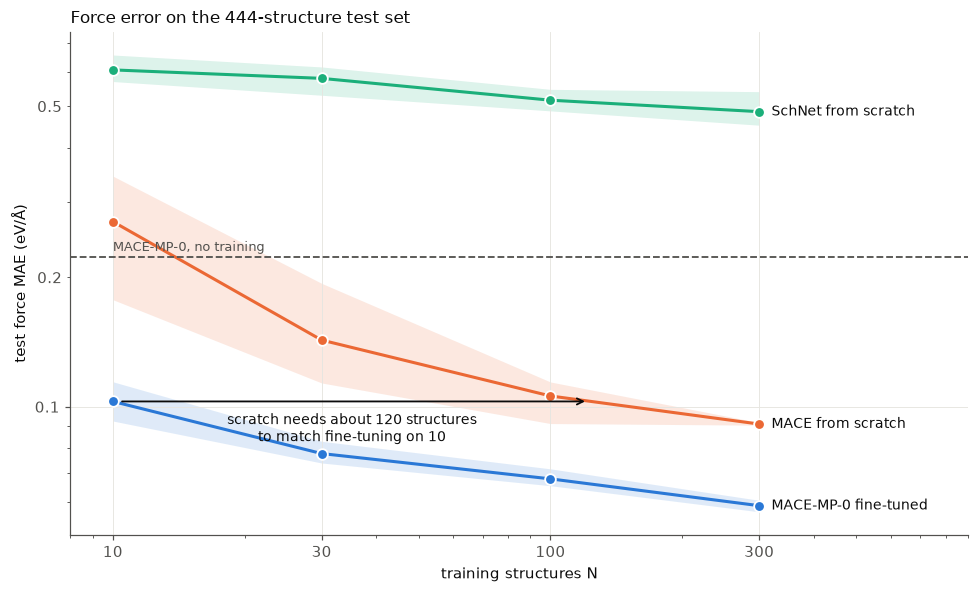

     MACE-MP-0 fine-tuned  MACE from scratch  SchNet from scratch
N                                                                
10                  0.103              0.269                0.607
30                  0.078              0.143                0.580
100                 0.068              0.106                0.516
300                 0.059              0.091                0.486
zero-shot MACE-MP-0: 0.223


In [2]:
def curve(metric, group="all", data=lc):
    s = data[data.group.eq(group)]
    return s.groupby(["approach", "N"])[metric].agg(["mean", "min", "max"]).reset_index()

def plot_curves(ax, metric, group="all", label_ends=True, zero=True):
    c = curve(metric, group)
    for ap, (name, col) in APPROACHES.items():
        s = c[c.approach.eq(ap)]
        ax.fill_between(s.N, s["min"], s["max"], color=col, alpha=0.15, lw=0)
        ax.plot(s.N, s["mean"], color=col, lw=2, marker="o", ms=7, mec="white", mew=1.2, label=name)
        if label_ends:
            ax.annotate(name, (s.N.iloc[-1], s["mean"].iloc[-1]), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=9, color=INK)
    if zero and pd.notna(zs.loc[group, metric]):
        ax.axhline(zs.loc[group, metric], color=MUTED, lw=1.2, ls="--")
        ax.annotate("MACE-MP-0, no training", (10, zs.loc[group, metric]), xytext=(0, 4),
                    textcoords="offset points", fontsize=8.5, color=MUTED)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks([10, 30, 100, 300]); ax.set_xticklabels(["10", "30", "100", "300"]); ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}" if f"{v:.0e}"[0] in "125" else ""))
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}" if f"{v:.0e}"[0] in "125" else ""))

def n_to_reach(target, ap, metric="force"):
    # log-log interpolation along the mean curve; None if the curve never gets that low
    s = curve(metric)
    s = s[s.approach.eq(ap)]
    x, y = np.log(s.N.values), np.log(s["mean"].values)
    for i in range(len(x) - 1):
        if y[i] >= np.log(target) >= y[i + 1]:
            t = (np.log(target) - y[i]) / (y[i + 1] - y[i])
            return float(np.exp(x[i] + t * (x[i + 1] - x[i])))
    return None

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_curves(ax, "force")
ft10 = curve("force").query("approach == 'mace_mp0_finetune' and N == 10")["mean"].item()
n_match = n_to_reach(ft10, "mace_scratch")
if n_match:
    ax.annotate("", xy=(n_match, ft10), xytext=(10, ft10),
                arrowprops=dict(arrowstyle="->", color=INK, lw=1.2, shrinkA=6, shrinkB=4))
    ax.annotate(f"scratch needs about {round(n_match, -1):.0f} structures\nto match fine-tuning on 10",
                (np.sqrt(10 * n_match), ft10), xytext=(0, -26), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
ax.set_xlim(8, 900)
ax.set_xlabel("training structures N"); ax.set_ylabel("test force MAE (eV/Å)")
ax.set_title("Force error on the 444-structure test set", loc="left", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

tab = curve("force").pivot(index="N", columns="approach", values="mean")[list(APPROACHES)]
tab.columns = [APPROACHES[a][0] for a in tab.columns]
print(tab.round(3).to_string()); print(f"zero-shot MACE-MP-0: {zs.loc['all', 'force']:.3f}")

What the picture says:

- **The blue line starts where the orange line ends up.** Fine-tuning on 10 structures (0.103 eV/Å) is what
  scratch MACE reaches at about 120 structures. That is the "about 10 times less data" claim, measured on our data.
- **The blue band is thin and the orange band is wide at small N.** Fine-tuning hardly depends on *which* 10
  structures you draw; scratch MACE does (0.18 to 0.34 eV/Å at N = 10). With very little data, the pretrained model
  gives you predictability as well as accuracy.
- **Even 10 structures halve the zero-shot error** (0.223 to 0.103). The foundation model's mistakes are mostly a
  smooth, learnable SCAN-vs-PBE difference, and a few examples are enough to correct most of it.
- **SchNet improves slowly and stays far behind.** It sees only distances (our lmax 0 picture from stage 3), and more
  data does not buy back the missing angular information at these sizes.

## 2. A caveat: is scratch MACE finished training?

Each run had a fixed epoch budget (N=10: 200 epochs, 30: 100, 100: 50, 300: 30), so that the whole queue would fit
on the laptop. Fine-tuning starts from a good model and needs few epochs. Scratch MACE starts from random weights.
The question is whether it ran out of budget before it ran out of data. The curves below are the validation force
error during training (the 50-structure validation set, not the test set), seed 0 and seed 2.

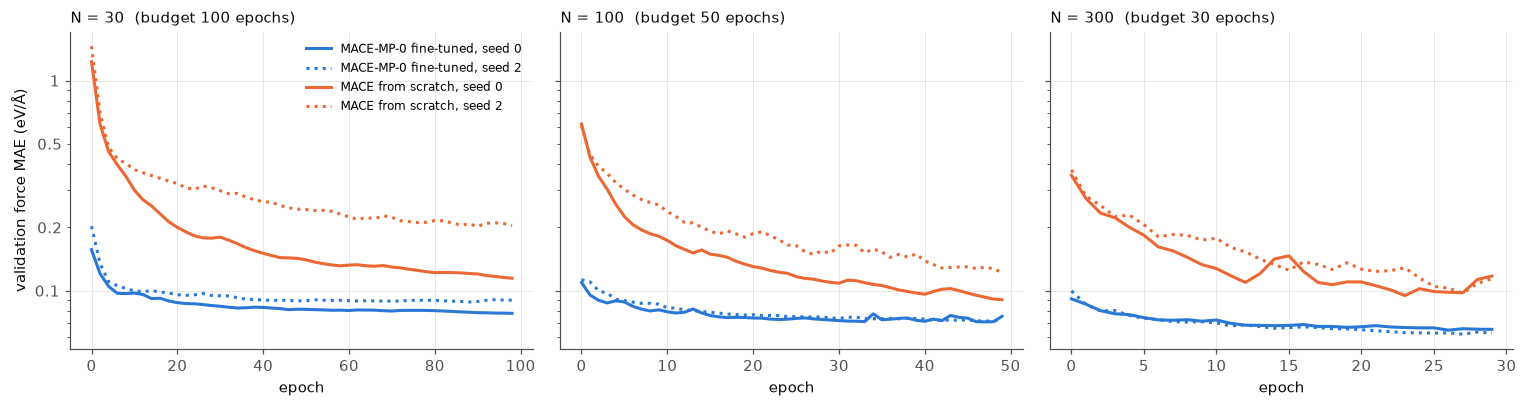

In [3]:
def val_curve(ap, seed, n):
    log = B / "runs" / ap / f"s{seed}_n{n}" / "train.log"
    if not log.exists():
        return None
    pts = [(int(m[1]), float(m[2])) for m in re.finditer(r"INFO: Epoch (\d+):.*?MAE_F=\s*([\d.]+)", log.read_text())]
    if not pts:
        return None
    ep = {}
    for e, f in pts:          # a resumed run repeats epochs; keep the last value written for each
        ep[e] = f
    e = np.array(sorted(ep)); return e, np.array([ep[k] for k in e]) / 1000

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, n in zip(axes, [30, 100, 300]):
    for ap in ["mace_mp0_finetune", "mace_scratch"]:
        name, col = APPROACHES[ap]
        for seed, ls in [(0, "-"), (2, ":")]:
            c = val_curve(ap, seed, n)
            if c is not None:
                ax.plot(c[0], c[1], color=col, lw=2, ls=ls, label=f"{name}, seed {seed}")
    ax.set_title(f"N = {n}  (budget {dict([(30, 100), (100, 50), (300, 30)])[n]} epochs)", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("epoch"); ax.set_yscale("log"); plain_log(ax)
axes[0].set_ylabel("validation force MAE (eV/Å)")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**The blue curves are flat well before the end; the orange ones are still trending down when the budget runs out.**
Fine-tuning has converged. Scratch MACE has not: at N = 30 it is still creeping down after 100 epochs, and at
N = 100 and 300 it is clearly still falling (the N = 300 curve is noisy, but the trend is down). Every run used
its full budget; none stopped early. So the flattening of the orange line in section 1 between N = 100 and 300 is
at least partly *our epoch budget*, not a limit of the model or the data.

What that means for the decision:

- **At equal training time, fine-tuning clearly wins.** This is the fair comparison if compute is the constraint,
  and it is a real constraint on a 4 GB laptop GPU.
- **At equal data with unlimited training, the gap at N = 300 is probably smaller than the plot shows.** Treat the
  orange points at N = 100 and 300 as upper bounds on the error.
- **Step 2 on the rented GPU should train the scratch runs to convergence**: train until early stopping kicks in,
  not to a fixed cap. Then this caveat goes away.

## 3. Where the error lives: per family

The overall force error mixes very different structures. From the data notebook: liquid frames have forces several
times larger than crystals, and they have the most atoms. Here are the same curves split into the four families.
All four panels share one y-axis, so heights can be compared directly.

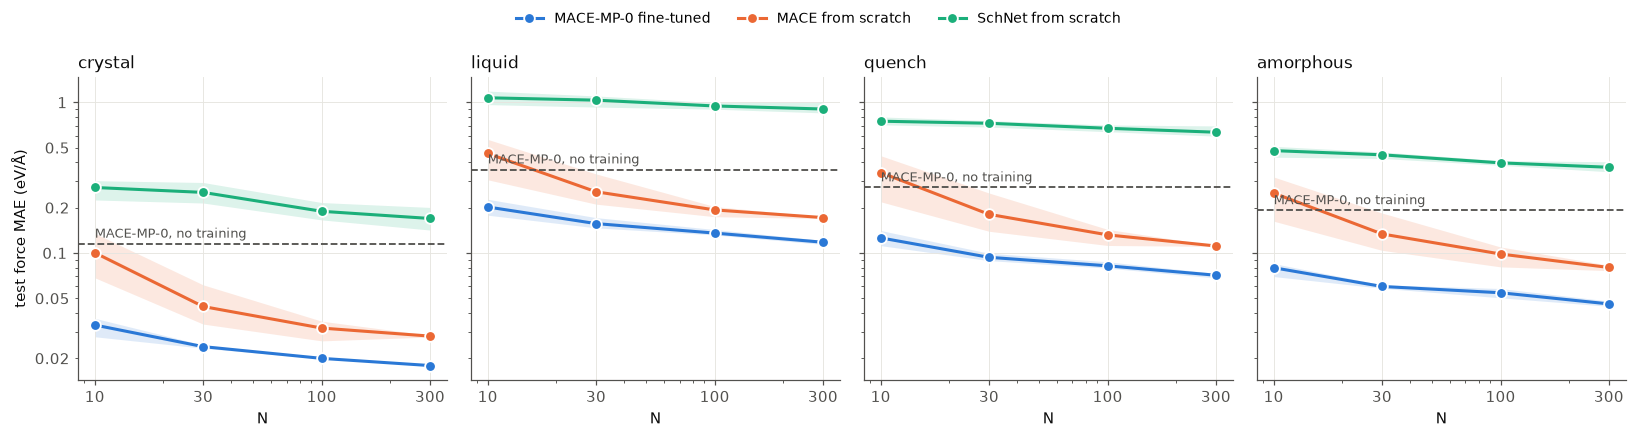

force MAE (eV/Å) at N = 300, mean of 3 seeds
           zero-shot  MACE-MP-0 fine-tuned  MACE from scratch  SchNet from scratch
group                                                                             
all            0.223                 0.059              0.091                0.486
crystal        0.115                 0.018              0.028                0.169
liquid         0.358                 0.118              0.172                0.903
quench         0.272                 0.071              0.111                0.633
amorphous      0.192                 0.046              0.080                0.371


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
for ax, g in zip(axes, GROUPS):
    plot_curves(ax, "force", g, label_ends=False)
    ax.set_title(g, loc="left", fontsize=11, color=INK); ax.set_xlabel("N")
axes[0].set_ylabel("test force MAE (eV/Å)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=9, ncol=3, loc="upper center")
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

t = lc[lc.N.eq(300)].groupby(["group", "approach"]).force.mean().unstack()[list(APPROACHES)].loc[["all"] + GROUPS]
t.insert(0, "zero-shot", zs.force.loc[["all"] + GROUPS])
t.columns = ["zero-shot"] + [APPROACHES[a][0] for a in APPROACHES]
print("force MAE (eV/Å) at N = 300, mean of 3 seeds"); print(t.round(3).to_string())

What to notice:

- **Crystals are easy for everyone except SchNet.** Both MACE variants end at 0.02 to 0.03 eV/Å on crystals.
- **Liquid is the hard part**, and the ranking holds there too. Hot liquid has many unusual local geometries
  (3- and 5-coordinated Si, short Si-Si contacts), and its errors are 3 to 7 times the crystal errors for every model.
- **The same order holds in every family, at every N.** The lead of fine-tuning over scratch at N = 300 is
  31 to 42 percent in each family. In absolute terms it is biggest on liquid (0.118 vs 0.172), in relative terms
  biggest on amorphous (0.046 vs 0.080).
- **Amorphous is the column closest to what the team cares about** (glass-like SiO2 variants). Fine-tuned MACE-MP-0
  is the best there at every N.
- **Zero-shot is already decent on crystals** (0.115) and worst on liquid (0.358). Pretraining data is mostly
  near-equilibrium crystals, so this is what you would expect.

## 4. Structures or atoms?

"N structures" hides a lot. A crystal frame has 6 to 144 atoms and a disordered frame has 192, so the same N gives
very different amounts of force data depending on the draw. Here every one of the 36 runs is a dot, placed by how
many *atoms* it trained on.

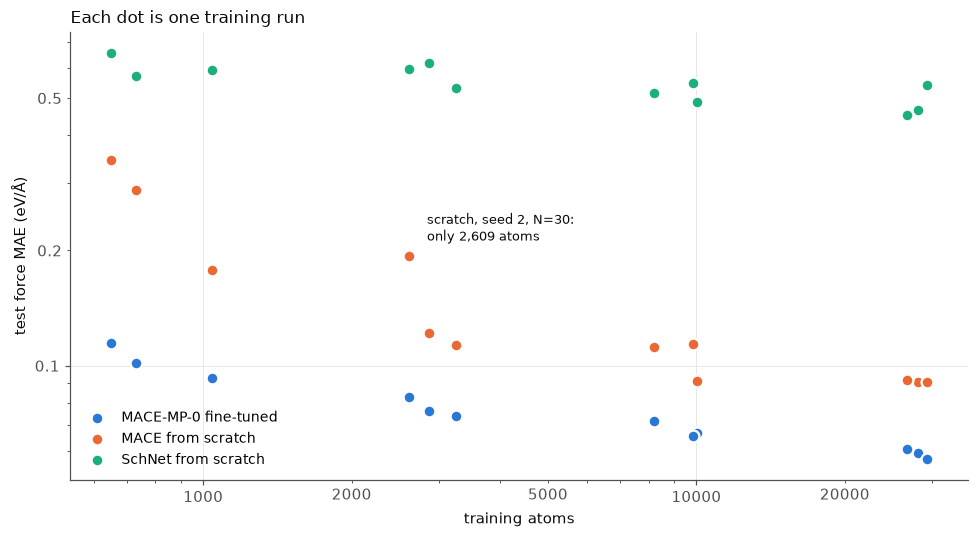

seed      0      1      2
N                        
10     1040    729    651
30     3259   2873   2609
100   10048   8207   9852
300   28095  26706  29378


In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
a = lc[lc.group.eq("all")]
for ap, (name, col) in APPROACHES.items():
    s = a[a.approach.eq(ap)]
    ax.scatter(s.atoms, s.force, s=60, color=col, edgecolors="white", linewidths=1.5, label=name, zorder=3)
odd = a[a.approach.eq("mace_scratch") & a.N.eq(30)].sort_values("force").iloc[-1]
ax.annotate(f"scratch, seed {odd.seed}, N=30:\nonly {odd.atoms:,} atoms", (odd.atoms, odd.force),
            xytext=(12, 10), textcoords="offset points", fontsize=8.5, color=INK)
ax.set_xscale("log"); ax.set_yscale("log"); plain_log(ax)
ax.set_xlabel("training atoms"); ax.set_ylabel("test force MAE (eV/Å)")
ax.legend(frameon=False, fontsize=9)
ax.set_title("Each dot is one training run", loc="left", fontsize=11, color=INK)
plt.tight_layout(); plt.show()
print(a.pivot_table(index="N", columns="seed", values="atoms", aggfunc="first").to_string())

Seen this way, much of the seed-to-seed spread for scratch MACE is just "how many atoms did this draw contain".
At N = 10 and N = 30 the scratch results line up exactly with atom count: the draw with the fewest atoms is the
worst, the one with the most is the best. The seed-2 N = 30 draw is the clearest case. Fine-tuning is barely
affected (its blue dots stay in a tight row).

For the team, this suggests counting the DFT budget in **atoms** (roughly, compute cost) rather than in structures
when comparing approaches. A few large disordered cells give more force labels than many small crystals.

## 5. The N = 10 energy mystery

Forces looked well-behaved. Energies did not: at N = 10, seeds 1 and 2 gave energy errors 10 to 20 times larger
than seed 0, for all three models. Below is every test structure's energy error for the scratch MACE runs at N = 10.
The y-axis is "symlog": linear near zero, logarithmic far out, so both small and huge errors fit.

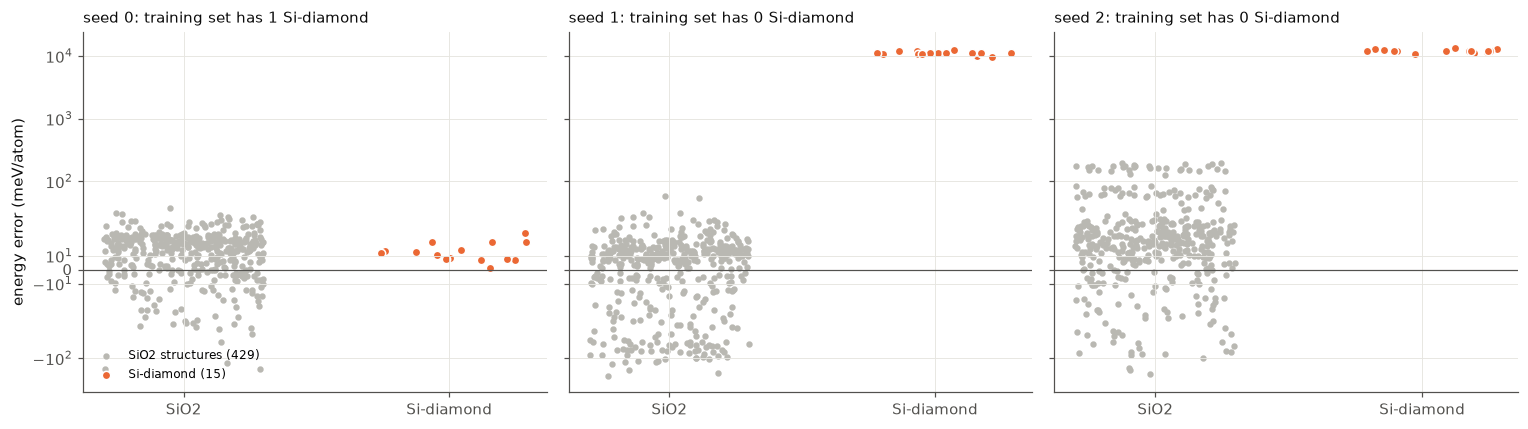

In [6]:
has_si = {}
for seed in [0, 1, 2]:
    fams = [x.info["family"] for x in read(B / f"data/lc/s{seed}_n10.xyz", ":")]
    has_si[seed] = fams.count("Si-diamond")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
rng = np.random.default_rng(0)
for ax, seed in zip(axes, [0, 1, 2]):
    s = per[per.approach.eq("mace_scratch") & per.N.eq(10) & per.seed.eq(seed)]
    si = s.family.eq("Si-diamond")
    jit = rng.uniform(-0.3, 0.3, len(s))
    ax.scatter(jit[~si], s.e_err_mev_atom[~si], s=10, color=FAINT, label="SiO2 structures (429)")
    ax.scatter(jit[si] + 1, s.e_err_mev_atom[si], s=30, color=ORANGE, edgecolors="white", linewidths=1,
               label="Si-diamond (15)")
    ax.set_yscale("symlog", linthresh=50); ax.set_xticks([0, 1]); ax.set_xticklabels(["SiO2", "Si-diamond"])
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_title(f"seed {seed}: training set has {has_si[seed]} Si-diamond", loc="left", fontsize=10, color=INK)
axes[0].set_ylabel("energy error (meV/atom)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**It's one family.** Si-diamond is pure silicon. Every other structure in the data is SiO2, where each Si is
surrounded by oxygen. So Si-diamond is the *only* place where the model can learn what a Si atom next to other
Si atoms is worth. Seed 0's 10 training structures happened to include one Si-diamond cell; seeds 1 and 2 had none.
Without it, the models guessed, and they were off by 3 to 12 **eV** per atom, about a thousand times the normal error.

Why it shows up in the energy and barely in the forces: Si-diamond is 15 of the 444 test structures but only 120 of
the 40,773 test atoms. The energy MAE averages over *structures*, so 15 structures × 3,000 to 12,000 meV/atom divided
by 444 adds 100 to 400 meV/atom to the average. The force MAE averages over *atoms*, so 120 atoms hardly move it.

Below, the energy curves recomputed two ways: SiO2 only, and Si-diamond alone.

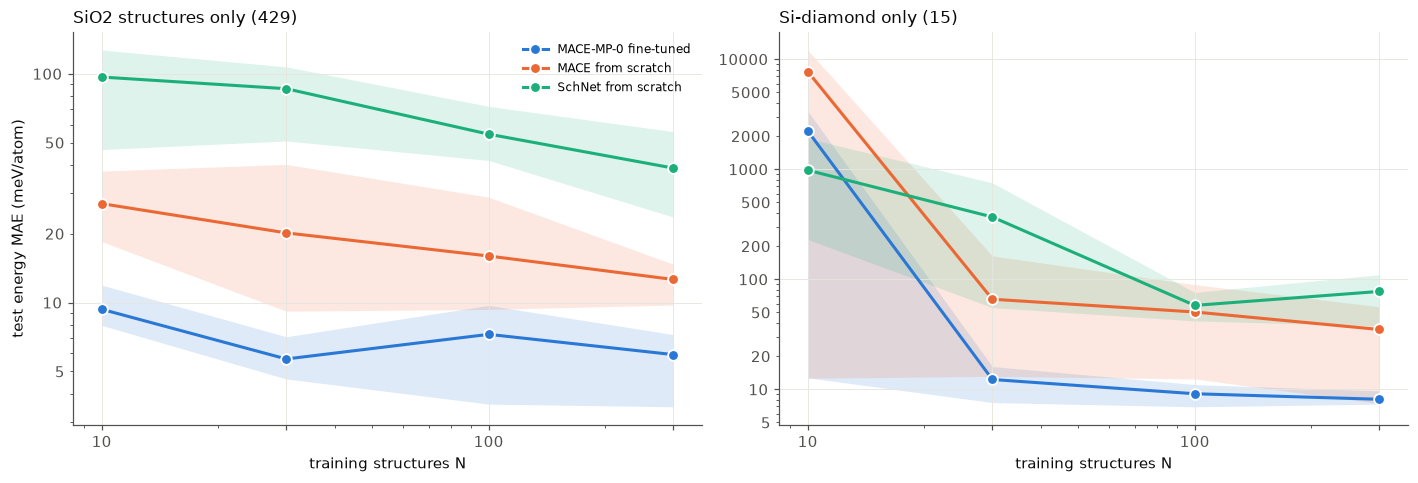

smallest N whose training set contains Si-diamond: {0: 10, 1: 30, 2: 30}


In [7]:
def energy_curve(mask):
    s = per[per.approach.isin(APPROACHES) & mask].assign(abs_e=lambda x: x.e_err_mev_atom.abs())
    return s.groupby(["approach", "seed", "N"]).abs_e.mean().groupby(["approach", "N"]).agg(["mean", "min", "max"]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (mask, title) in zip(axes, [(~per.family.eq("Si-diamond"), "SiO2 structures only (429)"),
                                     (per.family.eq("Si-diamond"), "Si-diamond only (15)")]):
    c = energy_curve(mask)
    for ap, (name, col) in APPROACHES.items():
        s = c[c.approach.eq(ap)]
        ax.fill_between(s.N, s["min"], s["max"], color=col, alpha=0.15, lw=0)
        ax.plot(s.N, s["mean"], color=col, lw=2, marker="o", ms=7, mec="white", mew=1.2, label=name)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks([10, 30, 100, 300]); ax.set_xticklabels(["10", "30", "100", "300"])
    plain_log(ax); ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    ax.set_title(title, loc="left", fontsize=11, color=INK); ax.set_xlabel("training structures N")
axes[0].set_ylabel("test energy MAE (meV/atom)"); axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

first = {}
order = json.load(open(B / "split_v1.json"))["orders"]
plan_val = set(json.load(open(B / "lc_plan_v1.json"))["val"])
for seed in [0, 1, 2]:
    for n in [10, 30, 100, 300]:
        fams = [x.info["family"] for x in read(B / f"data/lc/s{seed}_n{n}.xyz", ":")]
        if "Si-diamond" in fams:
            first[seed] = n; break
print("smallest N whose training set contains Si-diamond:", first)

With Si-diamond taken out, the energy curves behave like the force curves: fine-tuning lowest (5 to 10 meV/atom
at every N), then scratch MACE, then SchNet. The right panel shows the Si-diamond error collapsing as soon as a
seed's training set contains one Si cell, which happens by N = 30 for every seed. SchNet needs more Si examples
than the MACE models before it gets Si-diamond right.

Two lessons, one for benchmarking and one for the project:

- **An average over structures can be dominated by a small family.** From now on the benchmark reports SiO2 and
  Si-diamond separately.
- **Coverage matters more than count at small N.** A training set has to contain every *kind of local environment*
  the model will be asked about. Ten SiO2 structures teach nothing about Si-Si bonds. For the SiO2 variant this is the
  important version of the lesson: if the variant has a dopant or a defect environment that is not in the training
  data, more data of the other kinds will not fix it. The fine-tuned model was also off by 3 eV/atom here, so
  pretraining did not rescue it either.

## 6. Sidebar: why zero-shot forces are fair even though its energy is way off

The untouched MACE-MP-0 was trained on PBE energies with its own reference atoms, so its SCAN-silica energies are
off by about 2.7 eV/atom. Fitting one energy shift per element on the validation set brings that down from 2,704 to
44 meV/atom. The forces need no correction at all. The picture below shows why.

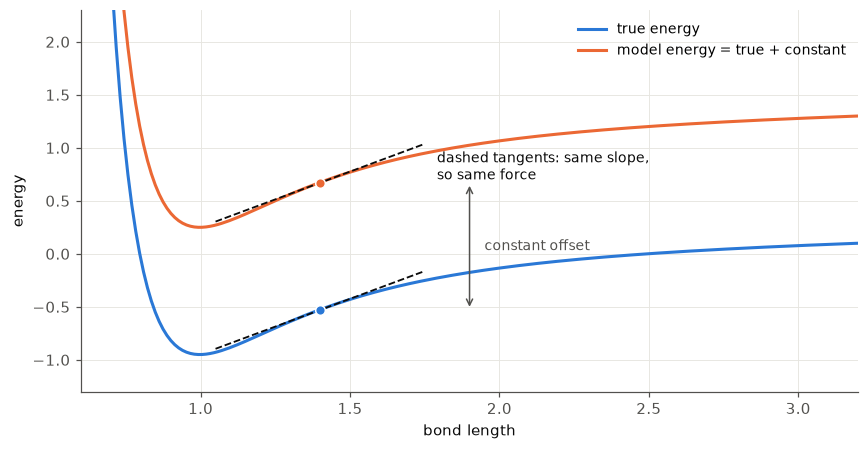

In [8]:
x = np.linspace(0.6, 3.2, 200)
E = (1 / x) ** 6 - 2 * (1 / x) ** 3 + 0.05 * x      # a toy bond energy curve
shift = 1.2
x0 = 1.4; dE = np.gradient(E, x)[np.argmin(abs(x - x0))]; E0 = E[np.argmin(abs(x - x0))]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(x, E, color=BLUE, lw=2, label="true energy")
ax.plot(x, E + shift, color=ORANGE, lw=2, label="model energy = true + constant")
for off, col in [(0, BLUE), (shift, ORANGE)]:
    t = np.linspace(x0 - 0.35, x0 + 0.35, 2)
    ax.plot(t, E0 + off + dE * (t - x0), color=INK, lw=1.2, ls="--")
    ax.scatter([x0], [E0 + off], s=40, color=col, edgecolors="white", zorder=3)
ax.annotate("", xy=(x0 + 0.5, E0 + shift), xytext=(x0 + 0.5, E0),
            arrowprops=dict(arrowstyle="<->", color=MUTED, lw=1))
ax.annotate("constant offset", (x0 + 0.55, E0 + shift / 2), fontsize=9, color=MUTED, va="center")
ax.annotate("dashed tangents: same slope,\nso same force", (x0 + 0.35, E0 + shift + dE * 0.35), xytext=(8, -4),
            textcoords="offset points", fontsize=9, color=INK, va="top")
ax.set_ylim(-1.3, 2.3); ax.set_xlim(0.6, 3.2)
ax.set_xlabel("bond length"); ax.set_ylabel("energy")
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout(); plt.show()

Force is minus the slope of the energy, F = −dE/dx. Adding a constant lifts the whole curve without tilting it,
so the slope at every point, and therefore the force on every atom, is unchanged. That is why the zero-shot force
error (0.223 eV/Å) is a fair number even though its raw energy error is 2,704 meV/atom.

The catch, which the data notebook found: MACE-MP-0's offset is *nearly* constant but differs by about 0.07 eV/atom
between quartz and glass. That part is not a constant, so it is a real error and it does tilt the curve. Fine-tuning
removes it, and that is part of why 10 structures already halve the force error.

## 7. Pressure

Pressure is the third label (from the stress), and it matters for anything involving density, which a glass
design-around does. Same layout as section 1.

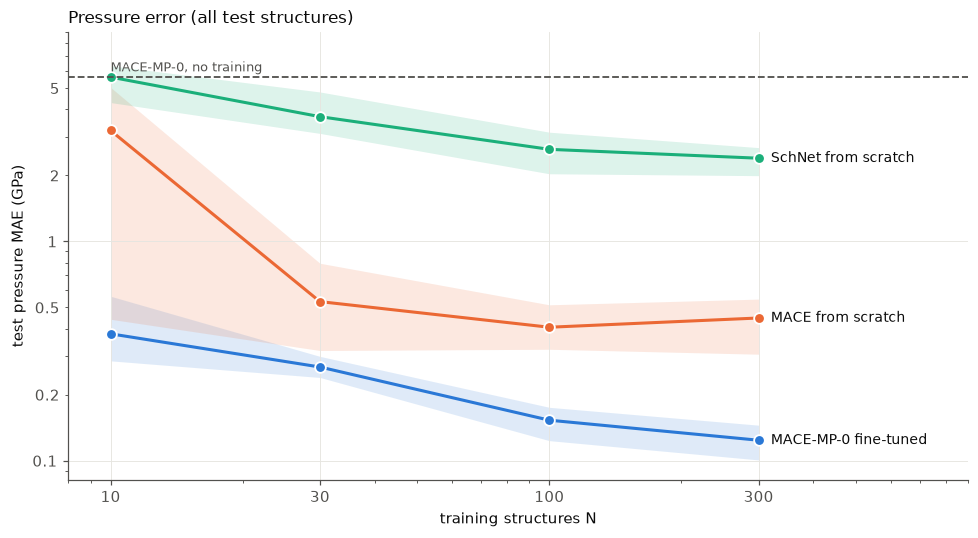

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_curves(ax, "pressure")
ax.set_xlim(8, 900); ax.set_ylim(top=9)
ax.set_xlabel("training structures N"); ax.set_ylabel("test pressure MAE (GPa)")
ax.set_title("Pressure error (all test structures)", loc="left", fontsize=11, color=INK)
plt.tight_layout(); plt.show()

Same ranking again. Fine-tuning goes from 5.6 GPa (zero-shot, mostly the PBE-vs-SCAN difference in equilibrium
volume) to about 0.4 GPa with 10 structures and 0.13 GPa with 300. Scratch MACE is about three times worse at
N = 300 and flat from 100 to 300 (the epoch budget again). Its N = 10 band is wide for the Si-diamond reason from
section 5: in seeds 1 and 2 the Si-diamond pressure is off by about 80 GPa. SchNet stays above 2 GPa. Silica glass
compresses by roughly 3 percent per GPa, so 2 GPa means a density error of several percent, too much for screening.

## Takeaways for the team

1. **Foundation-model fine-tuning needs about 10 times less data for the same force error**, measured on SCAN
   silica: 10 structures fine-tuned is as good as roughly 100 or more from scratch. It is also far less sensitive to
   which structures happen to be in the training set.
2. **The lead at 300 structures is partly a compute effect.** Scratch MACE was still improving when its epoch budget
   ran out. At equal compute fine-tuning wins clearly; at equal data with unlimited training the gap is probably smaller.
3. **Coverage beats count.** A missing chemical environment (here Si-Si bonds) produced errors of several eV/atom in
   every model, fine-tuned included, until one example was added. For the variant: make sure every dopant and defect
   environment appears in the training data.
4. **Distance-only models (SchNet) are not competitive** at these data sizes, for forces, energies or pressure.

**Step 2 (rented GPU):** N = 1,000 and the full pool of 2,495; scratch runs trained to convergence instead of to a
cap; report SiO2 and Si-diamond separately; then the stage-3 checks on the final models (rotation symmetry and NVE
energy conservation in MD).